In [73]:
import sys

print(sys.executable)

d:\Machine_learning\venv\Scripts\python.exe


pip install numpy pandas matplotlib seaborn scikit-learn jupyter ipykernel
python -m ipykernel install --user --name ml-env --display-name "Python (ML)"

In [ ]:
import numpy as np
import pandas as pd
import matplotlib
import sklearn


Pandas .xlsx files read karne ke liye normally openpyxl use karta hai.

In [ ]:


df = pd.read_excel("../data/Sample.xlsx")
df



,Unnamed: 0,gpa,iq,placement
0,0,6.8,123,1
1,1,5.9,106,0
2,2,5.3,121,0
3,3,7.4,132,1
4,4,5.8,142,0
5,5,6.2,118,1
6,6,7.1,128,1
7,7,5.5,110,0
8,8,6.7,135,1
9,9,5.1,102,0


In [76]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  25 non-null     int64  
 1   gpa         25 non-null     float64
 2   iq          25 non-null     int64  
 3   placement   25 non-null     int64  
dtypes: float64(1), int64(3)
memory usage: 932.0 bytes


In [77]:
df=df.iloc[:,1:]
df

,gpa,iq,placement
0,6.8,123,1
1,5.9,106,0
2,5.3,121,0
3,7.4,132,1
4,5.8,142,0
5,6.2,118,1
6,7.1,128,1
7,5.5,110,0
8,6.7,135,1
9,5.1,102,0


In [78]:
import matplotlib.pyplot as plt


In [79]:
print(df.head())
print(df.columns.tolist())

   gpa   iq  placement
0  6.8  123          1
1  5.9  106          0
2  5.3  121          0
3  7.4  132          1
4  5.8  142          0
['gpa', 'iq', 'placement']


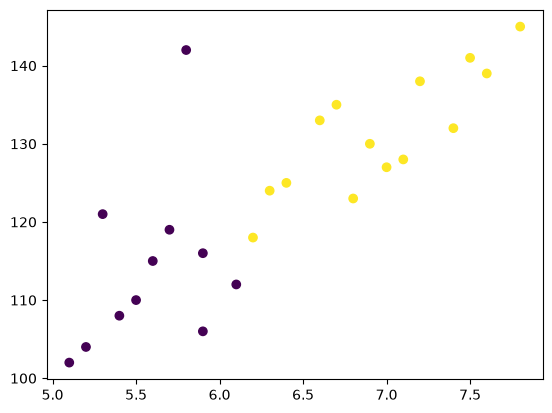

In [80]:
plt.scatter(df['gpa'],df['iq'],c=df['placement'])


In [81]:
x=df.iloc[:,0:2]
y=df.iloc[:,-1]
x.shape
y.shape

(25,)

In [82]:
from sklearn.model_selection import train_test_split

In [83]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.20)


In [84]:
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()


In [85]:
x_train= scaler.fit_transform(x_train)
x_test= scaler.fit_transform(x_test)
x_test

array([[-1.50147065, -1.62506771],
       [-0.36828525, -0.10833785],
       [-0.22663708,  0.        ],
       [ 0.62325197,  0.2166757 ],
       [ 1.47314102,  1.51672987]])

Lekin ek important correction: Logistic Regression "linear model" family ka model hai, aur iska naam regression hone ke bawajood iska common use classification ke liye hota hai.

In [86]:
from sklearn.linear_model import LogisticRegression
clf= LogisticRegression()
#model traing
clf.fit(x_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [87]:
y_pred=clf.predict(x_test)
y_pred

array([0, 0, 0, 1, 1])

In [88]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.6

<Axes: >

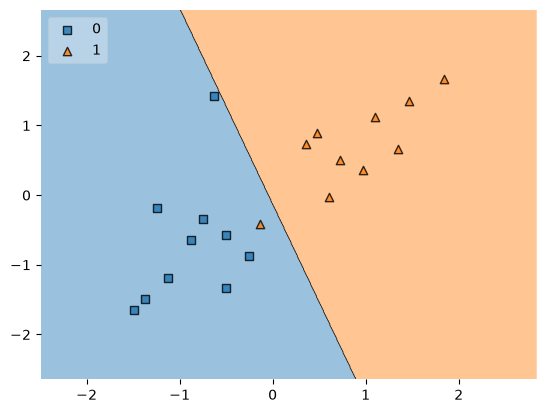

In [89]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(x_train, y_train.values, clf=clf, legend=2)


In [90]:
import pickle
pickle.dump(clf, open('model.pkl', 'wb'))